In [1]:
!pip -q install datasets timm gradio grad-cam

import os, random
from datasets import load_dataset

ds = load_dataset("ashraq/fashion-product-images-small", split="train")

# subCategory из датасета -> наши 5 классов
MAP = {"Shoes": "footwear", "Innerwear": "underwear", "Topwear": "topwear",
       "Headwear": "headwear", "Bottomwear": "bottomwear"}
CLASSES = sorted(MAP.values())

random.seed(42)
subs = ds["subCategory"]
idx = {c: [] for c in CLASSES}
for i, s in enumerate(subs):
    if s in MAP:
        idx[MAP[s]].append(i)

N = 300  # фото на класс
root = "/content/data"
for c in CLASSES:
    random.shuffle(idx[c])
    ids = idx[c][:N]
    n = len(ids); ntr = int(.7 * n); nva = int(.15 * n)
    parts = {"train": ids[:ntr], "val": ids[ntr:ntr + nva], "test": ids[ntr + nva:]}
    for sp, lst in parts.items():
        d = f"{root}/{sp}/{c}"; os.makedirs(d, exist_ok=True)
        for i in lst:
            ds[i]["image"].convert("RGB").save(f"{d}/{i}.jpg")
    print(f"{c:12s} total={n}  train={len(parts['train'])}  val={len(parts['val'])}  test={len(parts['test'])}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


README.md:   0%|          | 0.00/867 [00:00<?, ?B/s]

data/train-00000-of-00002-6cff4c59f91661(…): reconstructing file:   0%|          |  0.00B /  136MB            

data/train-00000-of-00002-6cff4c59f91661(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-bb459e5ac5f01e(…): reconstructing file:   0%|          |  0.00B /  135MB            

data/train-00001-of-00002-bb459e5ac5f01e(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/44072 [00:00<?, ? examples/s]

bottomwear   total=300  train=210  val=45  test=45
footwear     total=300  train=210  val=45  test=45
headwear     total=293  train=205  val=43  test=45
topwear      total=300  train=210  val=45  test=45
underwear    total=300  train=210  val=45  test=45


[baseline_cnn] ep1/15 train_loss=1.405 train_acc=0.398 val_loss=1.234 val_acc=0.561
[baseline_cnn] ep2/15 train_loss=1.207 train_acc=0.517 val_loss=1.054 val_acc=0.587
[baseline_cnn] ep3/15 train_loss=1.041 train_acc=0.620 val_loss=1.022 val_acc=0.587
[baseline_cnn] ep4/15 train_loss=0.960 train_acc=0.651 val_loss=0.819 val_acc=0.740
[baseline_cnn] ep5/15 train_loss=0.893 train_acc=0.687 val_loss=0.774 val_acc=0.709
[baseline_cnn] ep6/15 train_loss=0.807 train_acc=0.718 val_loss=0.718 val_acc=0.740
[baseline_cnn] ep7/15 train_loss=0.786 train_acc=0.731 val_loss=0.649 val_acc=0.816
[baseline_cnn] ep8/15 train_loss=0.751 train_acc=0.751 val_loss=0.806 val_acc=0.628
[baseline_cnn] ep9/15 train_loss=0.732 train_acc=0.756 val_loss=0.637 val_acc=0.803
[baseline_cnn] ep10/15 train_loss=0.688 train_acc=0.759 val_loss=0.573 val_acc=0.812
[baseline_cnn] ep11/15 train_loss=0.662 train_acc=0.779 val_loss=0.555 val_acc=0.807
[baseline_cnn] ep12/15 train_loss=0.618 train_acc=0.810 val_loss=0.518 val

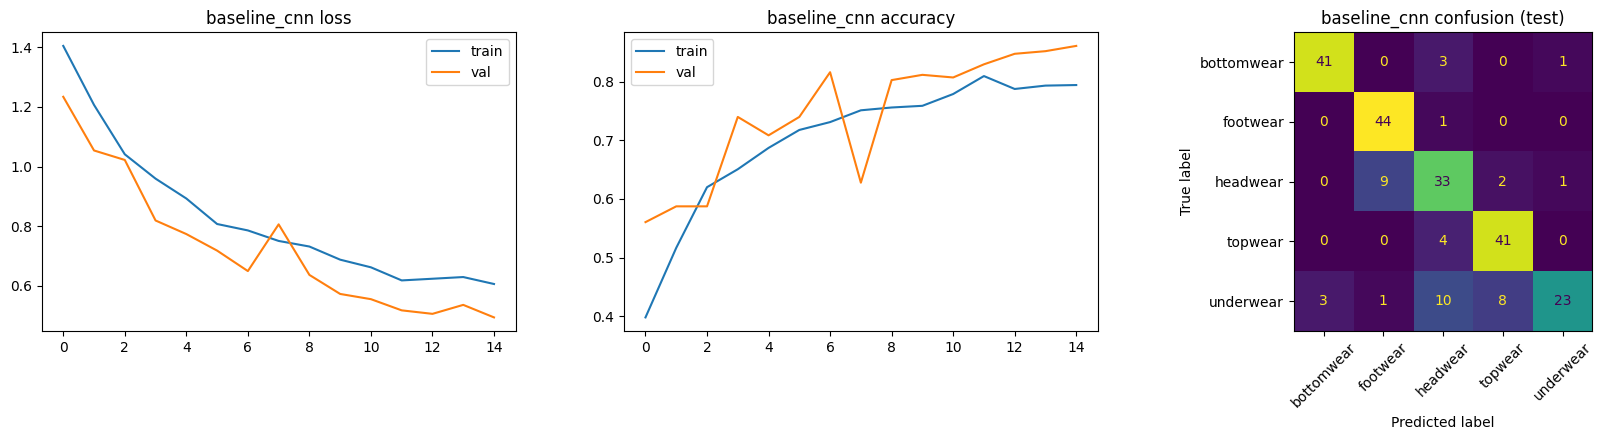

In [2]:
import torch, torch.nn as nn, timm, time, json, numpy as np, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score

dev = "cuda"
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tf = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15), transforms.ColorJitter(0.3, 0.3, 0.3),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
test_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def loaders(train_dir="/content/data/train"):
    tr = datasets.ImageFolder(train_dir, train_tf)
    va = datasets.ImageFolder("/content/data/val", test_tf)
    te = datasets.ImageFolder("/content/data/test", test_tf)
    return [DataLoader(d, batch_size=32, shuffle=(i == 0), num_workers=2) for i, d in enumerate([tr, va, te])]

class SimpleCNN(nn.Module):
    def __init__(s, n=5):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        s.f = nn.Sequential(blk(3, 32), blk(32, 64), blk(64, 128), blk(128, 256), nn.AdaptiveAvgPool2d(1))
        s.h = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n))
    def forward(s, x): return s.h(s.f(x))

def evaluate(model, dl):
    model.eval(); P, Y, loss = [], [], 0
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(dev), y.to(dev); o = model(x)
            loss += nn.functional.cross_entropy(o, y, reduction="sum").item()
            P += o.argmax(1).tolist(); Y += y.tolist()
    return loss / len(Y), accuracy_score(Y, P), f1_score(Y, P, average="macro"), Y, P

def train(model, name, epochs, lr, train_dir="/content/data/train"):
    tr, va, te = loaders(train_dir)
    model = model.to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    H = {k: [] for k in ["tr_loss", "va_loss", "tr_acc", "va_acc"]}; best = 0; t0 = time.time()
    for ep in range(epochs):
        model.train(); tl = c = n = 0
        for x, y in tr:
            x, y = x.to(dev), y.to(dev); opt.zero_grad()
            o = model(x); l = nn.functional.cross_entropy(o, y); l.backward(); opt.step()
            tl += l.item() * len(y); c += (o.argmax(1) == y).sum().item(); n += len(y)
        sch.step()
        vl, vacc, _, _, _ = evaluate(model, va)
        H["tr_loss"].append(tl / n); H["va_loss"].append(vl); H["tr_acc"].append(c / n); H["va_acc"].append(vacc)
        print(f"[{name}] ep{ep+1}/{epochs} train_loss={tl/n:.3f} train_acc={c/n:.3f} val_loss={vl:.3f} val_acc={vacc:.3f}")
        if vacc >= best: best = vacc; torch.save(model.state_dict(), f"/content/{name}.pt")
    ttime = time.time() - t0
    model.load_state_dict(torch.load(f"/content/{name}.pt"))
    _, acc, f1, Y, P = evaluate(model, te)
    model.eval(); x = torch.randn(1, 3, 224, 224).to(dev)
    with torch.no_grad():
        for _ in range(5): model(x)
        torch.cuda.synchronize(); t = time.time()
        for _ in range(50): model(x)
        torch.cuda.synchronize()
    lat = (time.time() - t) / 50 * 1000
    print(f"\n=== {name}: TEST acc={acc:.4f} macroF1={f1:.4f} latency={lat:.1f}ms train_time={ttime:.0f}s")
    print(classification_report(Y, P, target_names=CLASSES, digits=3))
    os.makedirs("/content/results", exist_ok=True)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    ax[0].plot(H["tr_loss"], label="train"); ax[0].plot(H["va_loss"], label="val"); ax[0].set_title(f"{name} loss"); ax[0].legend()
    ax[1].plot(H["tr_acc"], label="train"); ax[1].plot(H["va_acc"], label="val"); ax[1].set_title(f"{name} accuracy"); ax[1].legend()
    ConfusionMatrixDisplay(confusion_matrix(Y, P), display_labels=CLASSES).plot(ax=ax[2], xticks_rotation=45, colorbar=False)
    ax[2].set_title(f"{name} confusion (test)")
    plt.tight_layout(); plt.savefig(f"/content/results/{name}.png", dpi=120); plt.show()
    R = {"model": name, "test_acc": acc, "macro_f1": f1, "latency_ms": lat, "train_time_s": ttime,
         "params_M": sum(p.numel() for p in model.parameters()) / 1e6}
    json.dump(R, open(f"/content/results/{name}.json", "w"))
    return model, R

base, R1 = train(SimpleCNN(), "baseline_cnn", epochs=15, lr=1e-3)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[convnext_tiny] ep1/6 train_loss=0.393 train_acc=0.868 val_loss=0.097 val_acc=0.964
[convnext_tiny] ep2/6 train_loss=0.108 train_acc=0.968 val_loss=0.103 val_acc=0.969
[convnext_tiny] ep3/6 train_loss=0.090 train_acc=0.967 val_loss=0.077 val_acc=0.973
[convnext_tiny] ep4/6 train_loss=0.058 train_acc=0.982 val_loss=0.071 val_acc=0.978
[convnext_tiny] ep5/6 train_loss=0.029 train_acc=0.990 val_loss=0.042 val_acc=0.973
[convnext_tiny] ep6/6 train_loss=0.018 train_acc=0.995 val_loss=0.049 val_acc=0.973

=== convnext_tiny: TEST acc=0.9822 macroF1=0.9822 latency=5.9ms train_time=161s
              precision    recall  f1-score   support

  bottomwear      1.000     1.000     1.000        45
    footwear      1.000     1.000     1.000        45
    headwear      1.000     0.956     0.977        45
     topwear      0.957     1.000     0.978        45
   underwear      0.956     0.956     0.956        45

    accuracy                          0.982       225
   macro avg      0.983     0.982  

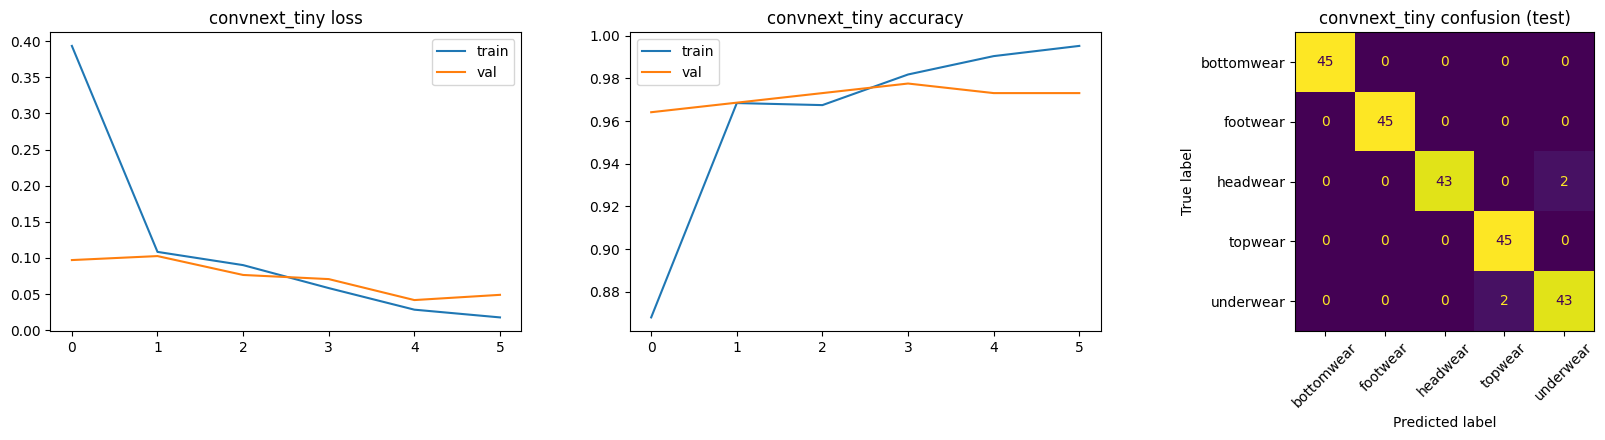

In [3]:
conv, R2 = train(timm.create_model("convnext_tiny", pretrained=True, num_classes=5),
                 "convnext_tiny", epochs=6, lr=1e-4)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


headwear -> generated 100
underwear -> generated 100


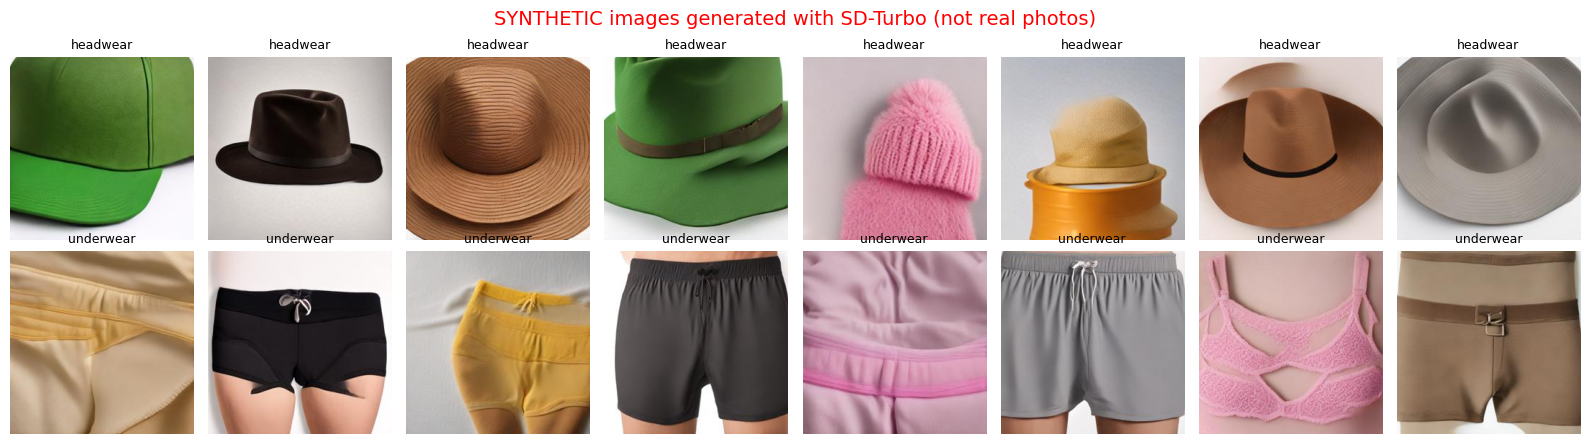

In [4]:
!pip -q install diffusers accelerate
import shutil, gc, glob
from diffusers import AutoPipelineForText2Image

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo", torch_dtype=torch.float16, variant="fp16").to(dev)
pipe.set_progress_bar_config(disable=True)

PROMPTS = {
    "headwear": ["baseball cap", "knit beanie hat", "sun hat", "bucket hat", "fedora hat",
                 "winter hat with pompom", "snapback cap", "straw hat"],
    "underwear": ["men's boxer briefs", "cotton briefs", "boxer shorts", "sports bra",
                  "thermal undershirt vest", "men's trunks underwear", "women's cotton panties", "bralette"],
}
COLORS = ["black", "white", "navy blue", "red", "grey", "beige", "green", "pink", "brown", "yellow"]
SYN_ROOT = "/content/data_syn/train"
shutil.copytree("/content/data/train", SYN_ROOT, dirs_exist_ok=True)

N_SYN = 100
random.seed(0)
for ci, (c, items) in enumerate(PROMPTS.items()):
    for k in range(N_SYN):
        p = (f"e-commerce product photo of a {random.choice(COLORS)} {random.choice(items)}, "
             f"isolated on plain white background, centered, studio lighting, no person")
        img = pipe(prompt=p, num_inference_steps=1, guidance_scale=0.0, height=512, width=512,
                   generator=torch.Generator(dev).manual_seed(1000 * ci + k)).images[0]
        img.resize((256, 256)).save(f"{SYN_ROOT}/{c}/synthetic_{k:03d}.jpg")
    print(c, "-> generated", N_SYN)

fig, ax = plt.subplots(2, 8, figsize=(16, 4.5))
for r, c in enumerate(PROMPTS):
    for j, f in enumerate(sorted(glob.glob(f"{SYN_ROOT}/{c}/synthetic_*.jpg"))[:8]):
        ax[r, j].imshow(plt.imread(f)); ax[r, j].axis("off"); ax[r, j].set_title(c, fontsize=9)
fig.suptitle("SYNTHETIC images generated with SD-Turbo (not real photos)", color="red", fontsize=14)
plt.tight_layout(); plt.savefig("/content/results/synthetic_samples.png", dpi=120); plt.show()

del pipe; gc.collect(); torch.cuda.empty_cache()

[baseline_cnn_syn] ep1/15 train_loss=1.382 train_acc=0.420 val_loss=1.425 val_acc=0.305
[baseline_cnn_syn] ep2/15 train_loss=1.150 train_acc=0.550 val_loss=1.037 val_acc=0.543
[baseline_cnn_syn] ep3/15 train_loss=1.041 train_acc=0.599 val_loss=0.966 val_acc=0.614
[baseline_cnn_syn] ep4/15 train_loss=0.937 train_acc=0.639 val_loss=1.047 val_acc=0.592
[baseline_cnn_syn] ep5/15 train_loss=0.912 train_acc=0.668 val_loss=0.791 val_acc=0.776
[baseline_cnn_syn] ep6/15 train_loss=0.816 train_acc=0.728 val_loss=0.723 val_acc=0.767
[baseline_cnn_syn] ep7/15 train_loss=0.795 train_acc=0.714 val_loss=0.737 val_acc=0.807
[baseline_cnn_syn] ep8/15 train_loss=0.752 train_acc=0.728 val_loss=0.724 val_acc=0.735
[baseline_cnn_syn] ep9/15 train_loss=0.717 train_acc=0.747 val_loss=0.670 val_acc=0.798
[baseline_cnn_syn] ep10/15 train_loss=0.701 train_acc=0.752 val_loss=0.604 val_acc=0.812
[baseline_cnn_syn] ep11/15 train_loss=0.678 train_acc=0.768 val_loss=0.602 val_acc=0.803
[baseline_cnn_syn] ep12/15 tra

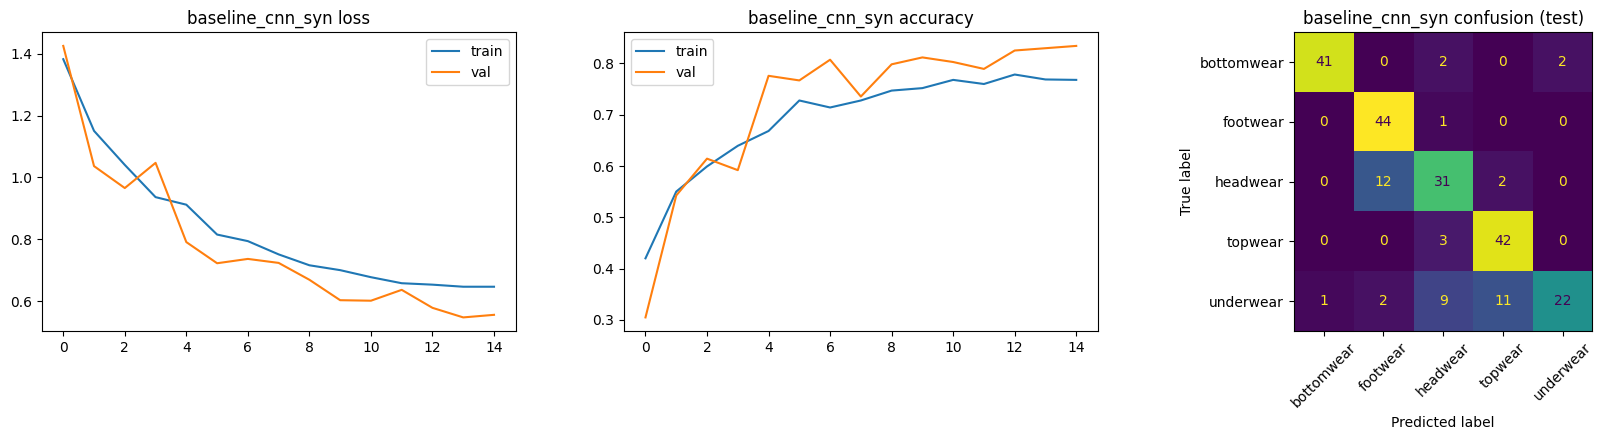

[convnext_tiny_syn] ep1/6 train_loss=0.346 train_acc=0.892 val_loss=0.136 val_acc=0.951
[convnext_tiny_syn] ep2/6 train_loss=0.138 train_acc=0.960 val_loss=0.103 val_acc=0.969
[convnext_tiny_syn] ep3/6 train_loss=0.063 train_acc=0.982 val_loss=0.115 val_acc=0.955
[convnext_tiny_syn] ep4/6 train_loss=0.026 train_acc=0.994 val_loss=0.058 val_acc=0.978
[convnext_tiny_syn] ep5/6 train_loss=0.016 train_acc=0.996 val_loss=0.077 val_acc=0.973
[convnext_tiny_syn] ep6/6 train_loss=0.012 train_acc=0.995 val_loss=0.077 val_acc=0.973

=== convnext_tiny_syn: TEST acc=0.9867 macroF1=0.9867 latency=6.8ms train_time=189s
              precision    recall  f1-score   support

  bottomwear      1.000     0.978     0.989        45
    footwear      1.000     1.000     1.000        45
    headwear      1.000     1.000     1.000        45
     topwear      0.978     0.978     0.978        45
   underwear      0.957     0.978     0.967        45

    accuracy                          0.987       225
   macr

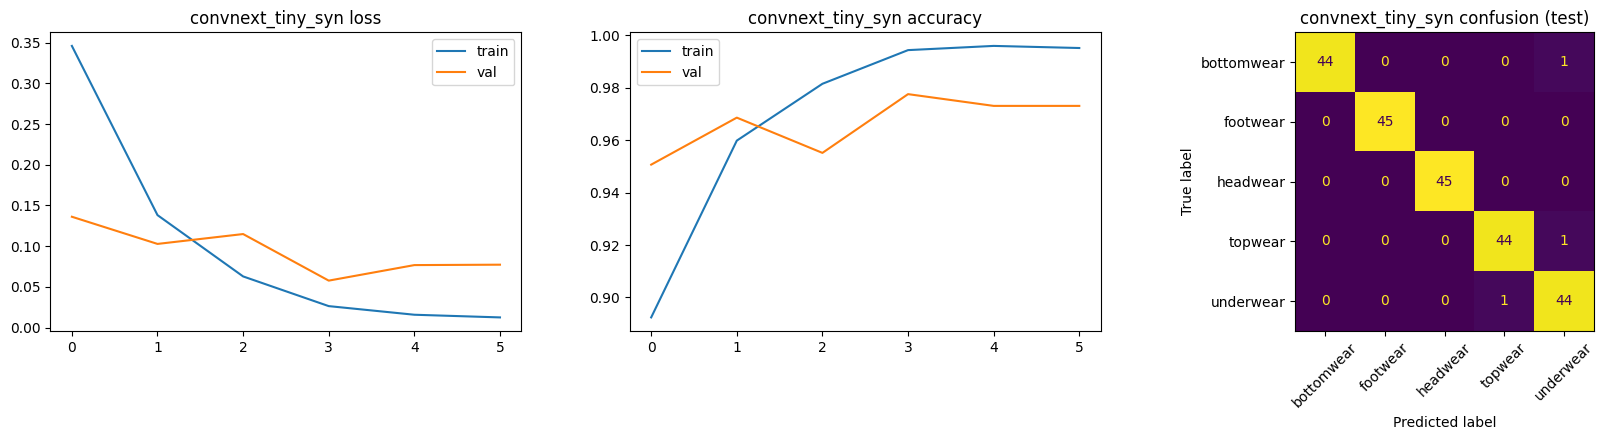

            model  test_acc  macro_f1  latency_ms  train_time_s  params_M
     baseline_cnn    0.8089    0.8018      0.7633       88.5026    0.3907
    convnext_tiny    0.9822    0.9822      5.9462      160.8688   27.8240
 baseline_cnn_syn    0.8000    0.7912      0.8143      115.0673    0.3907
convnext_tiny_syn    0.9867    0.9867      6.7572      189.1284   27.8240


In [5]:
import pandas as pd
base_syn, R3 = train(SimpleCNN(), "baseline_cnn_syn", epochs=15, lr=1e-3, train_dir=SYN_ROOT)
conv_syn, R4 = train(timm.create_model("convnext_tiny", pretrained=True, num_classes=5),
                     "convnext_tiny_syn", epochs=6, lr=1e-4, train_dir=SYN_ROOT)
df = pd.DataFrame([R1, R2, R3, R4])
print(df.round(4).to_string(index=False))
df.to_csv("/content/results/summary.csv", index=False)

TypeError: BaseCAM.__call__() missing 1 required positional argument: 'targets'

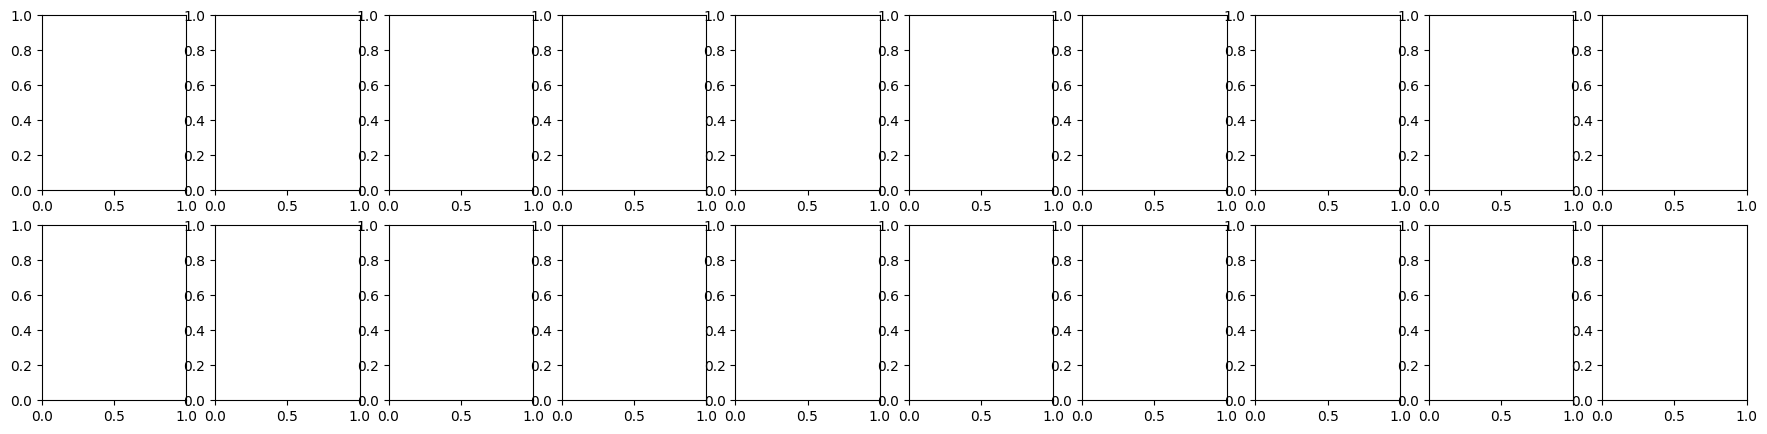

In [6]:
# ===== Colab cell: Grad-CAM gallery for the report + Gradio app =====
# Run after the training cells (uses CLASSES, test_tf, dev, timm, torch, glob, plt, np, time).
import gradio as gr, platform
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image

MODEL_NAME = "convnext_tiny_syn"  # best model: test acc 0.987, macro-F1 0.987
model = timm.create_model("convnext_tiny", pretrained=False, num_classes=5)
model.load_state_dict(torch.load(f"/content/{MODEL_NAME}.pt")); model.to(dev).eval()
cam = GradCAM(model=model, target_layers=[model.stages[-1]])

def run(img):
    x = test_tf(img).unsqueeze(0).to(dev)
    with torch.no_grad(): p = torch.softmax(model(x), 1)[0].cpu()
    g = cam(input_tensor=x)[0]
    rgb = np.array(img.resize((224, 224))).astype(np.float32) / 255
    return p, show_cam_on_image(rgb, g, use_rgb=True)

# --- Grad-CAM gallery (2 test images per class) for the report ---
fig, ax = plt.subplots(2, 10, figsize=(22, 5))
for ci, c in enumerate(CLASSES):
    for k, f in enumerate(sorted(glob.glob(f"/content/data/test/{c}/*.jpg"))[:2]):
        img = Image.open(f).convert("RGB"); p, heat = run(img)
        col = ci * 2 + k
        ax[0, col].imshow(img.resize((224, 224))); ax[0, col].set_title(f"true: {c}", fontsize=9)
        ax[1, col].imshow(heat); ax[1, col].set_title(f"pred: {CLASSES[p.argmax()]} {p.max():.2f}", fontsize=9)
        ax[0, col].axis("off"); ax[1, col].axis("off")
fig.suptitle(f"Grad-CAM explanations ({MODEL_NAME})", fontsize=14)
plt.tight_layout(); plt.savefig("/content/results/gradcam_examples.png", dpi=120); plt.show()

# --- Gradio app ---
LAT = []
def predict(img):
    if img is None: return None, None, ""
    img = img.convert("RGB")
    x = test_tf(img).unsqueeze(0).to(dev)
    torch.cuda.synchronize(); t = time.time()
    with torch.no_grad(): p = torch.softmax(model(x), 1)[0].cpu()
    torch.cuda.synchronize(); ms = (time.time() - t) * 1000; LAT.append(ms)
    _, heat = run(img)
    info = (f"Latency: {ms:.1f} ms (avg {np.mean(LAT):.1f} ms over {len(LAT)} runs)\n"
            f"Device: {torch.cuda.get_device_name(0)} | torch {torch.__version__} | Python {platform.python_version()}\n"
            f"Model: {MODEL_NAME}")
    return {c: float(p[i]) for i, c in enumerate(CLASSES)}, heat, info

examples = [sorted(glob.glob(f"/content/data/test/{c}/*.jpg"))[0] for c in CLASSES]
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", sources=["upload", "webcam"], label="Upload a photo or use the camera"),
    outputs=[gr.Label(num_top_classes=5, label="Prediction"),
             gr.Image(label="Grad-CAM explanation"),
             gr.Textbox(label="Latency & environment")],
    examples=examples,
    title="Clothing Classifier: ConvNeXt-Tiny + Grad-CAM",
    description=("Classes: bottomwear, footwear, headwear, topwear, underwear. "
                 "Part of the training data is SYNTHETIC (generated with SD-Turbo) and labeled as such. "
                 "Uploaded images are not stored."),
)
demo.launch(share=True)


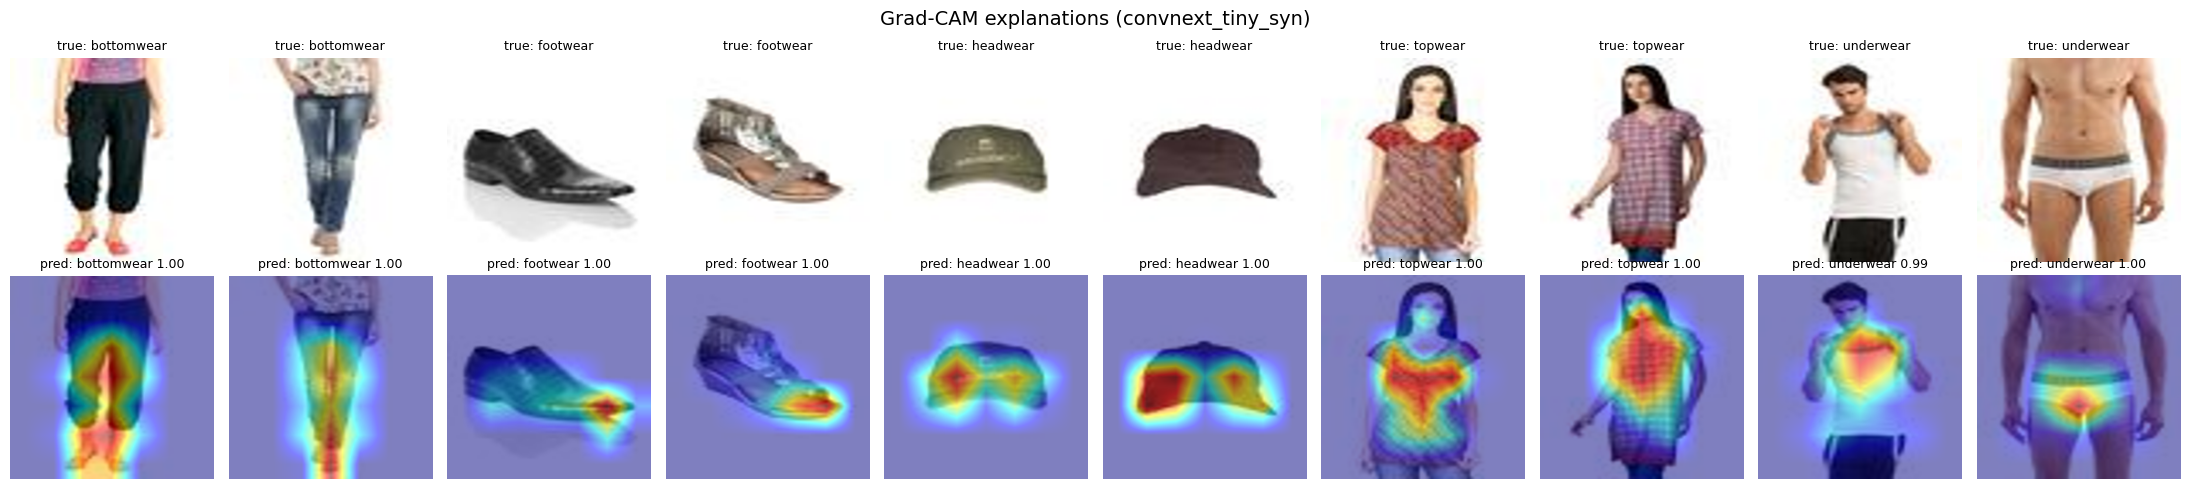

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://66897bb22e2bdc76c0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [7]:
# ===== Colab cell: Grad-CAM gallery for the report + Gradio app =====
# Run after the training cells (uses CLASSES, test_tf, dev, timm, torch, glob, plt, np, time).
import gradio as gr, platform
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image

MODEL_NAME = "convnext_tiny_syn"  # best model: test acc 0.987, macro-F1 0.987
model = timm.create_model("convnext_tiny", pretrained=False, num_classes=5)
model.load_state_dict(torch.load(f"/content/{MODEL_NAME}.pt")); model.to(dev).eval()
cam = GradCAM(model=model, target_layers=[model.stages[-1]])

def run(img):
    x = test_tf(img).unsqueeze(0).to(dev)
    with torch.no_grad(): p = torch.softmax(model(x), 1)[0].cpu()
    g = cam(input_tensor=x, targets=None)[0]
    rgb = np.array(img.resize((224, 224))).astype(np.float32) / 255
    return p, show_cam_on_image(rgb, g, use_rgb=True)

# --- Grad-CAM gallery (2 test images per class) for the report ---
fig, ax = plt.subplots(2, 10, figsize=(22, 5))
for ci, c in enumerate(CLASSES):
    for k, f in enumerate(sorted(glob.glob(f"/content/data/test/{c}/*.jpg"))[:2]):
        img = Image.open(f).convert("RGB"); p, heat = run(img)
        col = ci * 2 + k
        ax[0, col].imshow(img.resize((224, 224))); ax[0, col].set_title(f"true: {c}", fontsize=9)
        ax[1, col].imshow(heat); ax[1, col].set_title(f"pred: {CLASSES[p.argmax()]} {p.max():.2f}", fontsize=9)
        ax[0, col].axis("off"); ax[1, col].axis("off")
fig.suptitle(f"Grad-CAM explanations ({MODEL_NAME})", fontsize=14)
plt.tight_layout(); plt.savefig("/content/results/gradcam_examples.png", dpi=120); plt.show()

# --- Gradio app ---
LAT = []
def predict(img):
    if img is None: return None, None, ""
    img = img.convert("RGB")
    x = test_tf(img).unsqueeze(0).to(dev)
    torch.cuda.synchronize(); t = time.time()
    with torch.no_grad(): p = torch.softmax(model(x), 1)[0].cpu()
    torch.cuda.synchronize(); ms = (time.time() - t) * 1000; LAT.append(ms)
    _, heat = run(img)
    info = (f"Latency: {ms:.1f} ms (avg {np.mean(LAT):.1f} ms over {len(LAT)} runs)\n"
            f"Device: {torch.cuda.get_device_name(0)} | torch {torch.__version__} | Python {platform.python_version()}\n"
            f"Model: {MODEL_NAME}")
    return {c: float(p[i]) for i, c in enumerate(CLASSES)}, heat, info

examples = [sorted(glob.glob(f"/content/data/test/{c}/*.jpg"))[0] for c in CLASSES]
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", sources=["upload", "webcam"], label="Upload a photo or use the camera"),
    outputs=[gr.Label(num_top_classes=5, label="Prediction"),
             gr.Image(label="Grad-CAM explanation"),
             gr.Textbox(label="Latency & environment")],
    examples=examples,
    title="Clothing Classifier: ConvNeXt-Tiny + Grad-CAM",
    description=("Classes: bottomwear, footwear, headwear, topwear, underwear. "
                 "Part of the training data is SYNTHETIC (generated with SD-Turbo) and labeled as such. "
                 "Uploaded images are not stored."),
)
demo.launch(share=True)


In [8]:
!zip -rq /content/results.zip /content/results
from google.colab import files; files.download("/content/results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>